# Experiment 4 : Spatial Signaling and Proliferation

**Drug Modeled:** Gefitinib

**Condition Tested:** EGFR signaling and proliferation rates in a drug gradient

**Research Question:** How do spatial drug gradients create biological response gradients?

In [6]:

import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# EXPERIMENT 4: GEFiTINIB HETEROGENEOUS DIFFUSION
# Conservative finite-volume implementation
# ==========================================

# Spatial domain
L = 0.2                 # cm (2 mm)
nx = 200                # number of cells
dx = L / nx

# Cell-centered spatial coordinates
x = (np.arange(nx) + 0.5) * dx

# Time domain
T = 3600                # seconds
nt = 10000
dt = T / nt

# Tissue layer boundaries
boundary_1 = 0.05       # cm (0.5 mm)
boundary_2 = 0.12       # cm (1.2 mm)

# Diffusion coefficients
D1 = 5e-7               # outer layer
D2 = 1e-7               # dense middle layer
D3 = 5e-7               # inner layer

# Spatial diffusion coefficient
D = np.full(nx, D1)
D[x >= boundary_1] = D2
D[x >= boundary_2] = D3

# Harmonic mean at internal cell faces
D_face = (
    2 * D[:-1] * D[1:]
    / (D[:-1] + D[1:])
)

# Constant gefitinib source
C_source = 1.0

# Initial concentration
C = np.zeros(nx)

# Saving
save_every = 50
saved_profiles = [C.copy()]
saved_times = [0.0]

# Mass balance tracking
cumulative_influx = 0.0

# Stability parameter
r_max = dt * np.max(D) / dx**2

assert r_max <= 1/3, "Time step exceeds chosen positivity limit."


In [7]:
# ==========================================
# TIME-STEPPING LOOP
# ==========================================

for step in range(nt):

    # Flux at every cell face
    J = np.zeros(nx + 1)

    # Left boundary: fixed source concentration
    # Half-cell distance between source and first cell center
    J[0] = D[0] * (C_source - C[0]) / (dx / 2)

    # Internal fluxes
    J[1:nx] = (
        -D_face * (C[1:] - C[:-1]) / dx
    )

    # Right boundary: zero flux
    J[nx] = 0.0

    # Track drug entering through the source boundary
    cumulative_influx += J[0] * dt

    # Conservative finite-volume update
    C = C + (dt / dx) * (J[:-1] - J[1:])

    # Save concentration profiles
    if (step + 1) % save_every == 0 or step == nt - 1:
        saved_profiles.append(C.copy())
        saved_times.append((step + 1) * dt)

# Convert saved profiles to arrays
C_field = np.array(saved_profiles)
saved_times = np.array(saved_times)

# Final concentration profile
C_final = C.copy()

print("Simulation completed.")
print(f"Spatial cells: {nx}")
print(f"Time step: {dt:.4f} s")
print(f"Final time: {T:.1f} s")
print(f"Minimum concentration: {C.min():.8e}")
print(f"Maximum concentration: {C.max():.8f}")

Simulation completed.
Spatial cells: 200
Time step: 0.3600 s
Final time: 3600.0 s
Minimum concentration: 3.10001547e-06
Maximum concentration: 0.99461038


In [8]:

# ==========================================
# NUMERICAL VALIDATION
# ==========================================

# 1. Nonnegative concentration
assert np.min(C_field) >= -1e-12

# 2. Concentration does not exceed source
assert np.max(C_field) <= C_source + 1e-10

# 3. Zero-flux distal boundary
distal_flux = 0.0

# 4. Mass conservation
final_mass = dx * np.sum(C_final)

mass_balance_error = final_mass - cumulative_influx

relative_mass_error = (
    abs(mass_balance_error)
    / max(abs(final_mass), 1e-15)
)

# 5. Print results
print("VALIDATION RESULTS")
print("------------------")

print("Nonnegative concentrations:",
      np.min(C_field) >= -1e-12)

print("Concentration bounded by source:",
      np.max(C_field) <= C_source + 1e-10)

print("Distal boundary flux:", distal_flux)

print("Final integrated concentration:", final_mass)

print("Cumulative source influx:", cumulative_influx)

print("Mass balance error:", mass_balance_error)

print("Relative mass balance error:", relative_mass_error)

assert relative_mass_error < 1e-10


VALIDATION RESULTS
------------------
Nonnegative concentrations: True
Concentration bounded by source: True
Distal boundary flux: 0.0
Final integrated concentration: 0.04605722260839597
Cumulative source influx: 0.04605722260839617
Mass balance error: -2.0122792321330962e-16
Relative mass balance error: 4.369085060214354e-15


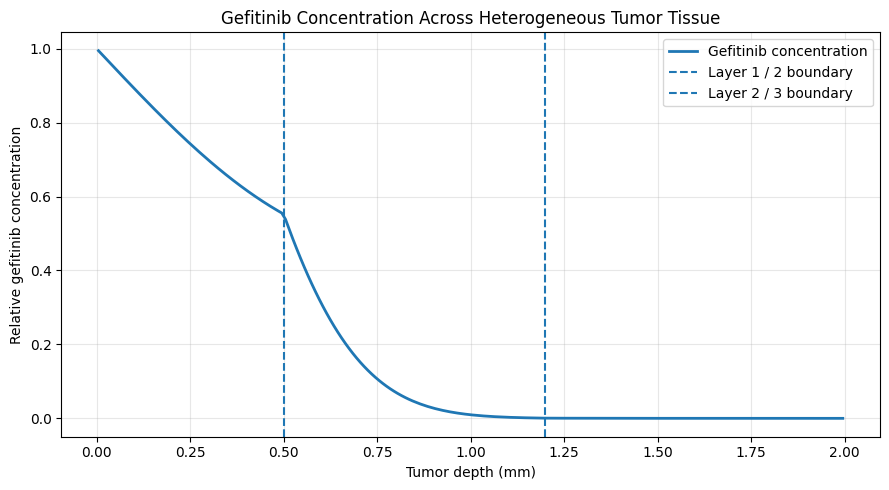

In [9]:

# Final spatial concentration profile

plt.figure(figsize=(9, 5))

plt.plot(
    x * 10,
    C_final,
    linewidth=2,
    label="Gefitinib concentration"
)

plt.axvline(boundary_1 * 10, linestyle="--",
            label="Layer 1 / 2 boundary")

plt.axvline(boundary_2 * 10, linestyle="--",
            label="Layer 2 / 3 boundary")

plt.xlabel("Tumor depth (mm)")
plt.ylabel("Relative gefitinib concentration")

plt.title(
    "Gefitinib Concentration Across Heterogeneous Tumor Tissue"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


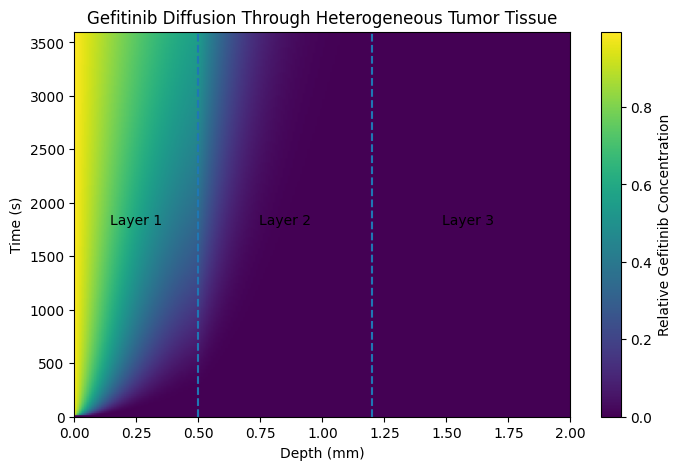

In [10]:
# Plot

C_field = np.array(saved_profiles)

plt.figure(figsize=(8, 5))

plt.imshow(C_field, aspect='auto', origin='lower', extent=[0, L * 10, 0, T])

# Labels and formatting

plt.colorbar(label='Relative Gefitinib Concentration')

plt.xlabel('Depth (mm)')
plt.ylabel('Time (s)')

plt.title('Gefitinib Diffusion Through Heterogeneous Tumor Tissue')

plt.axvline(boundary_1 * 10, linestyle='--')
plt.axvline(boundary_2 * 10, linestyle='--')

plt.savefig(
    'figures/exp04_heter_map_baseline.png',
    dpi=150,
    bbox_inches='tight'
)

plt.annotate('Layer 1', xy=(boundary_1 * 5, T / 2), fontsize=10, ha='center')
plt.annotate('Layer 2', xy=((boundary_1 + boundary_2) * 5, T / 2), fontsize=10, ha='center')
plt.annotate('Layer 3', xy=((boundary_1 + boundary_2 + L) * 8.57 / 2, T / 2), fontsize=10, ha='center')

plt.show()

## Figure 4A

**Figure 4A.** Spatial distribution of normalized gefitinib concentration within heterogeneous tumor tissue used as the input to the signaling model. The concentration field was generated using the heterogeneous diffusion model developed in Experiment 2 and serves as the basis for predicting spatial patterns of EGFR inhibition, ERK signaling activity, and cellular proliferation.

### Observations

* Highest gefitinib concentrations occur adjacent to the blood vessel.
* Concentration decreases with increasing tissue depth.
* The dense middle layer produces reduced drug penetration into deeper tissue.
* Spatial concentration gradients persist throughout the tumor.

### Interpretation

The concentration field represents the local drug exposure experienced by cells throughout the tumor. Because EGFR inhibition depends on local gefitinib concentration, different regions are expected to experience different levels of receptor inhibition. The heterogeneous concentration distribution establishes the initial conditions for downstream signaling analysis.

### Discussion

The heterogeneous concentration field generated in Experiment 2 provides the spatial input for the pharmacodynamic model. Regions of reduced drug concentration are therefore expected to exhibit reduced EGFR inhibition relative to areas proximal to the vascular source.

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# Paramters

# New copy of concentration field from figure 4A
C_gefit_field = C_field

# Hill coefficient
n = 1

# Literature IC_50 value, concentration of gefitinib to achieve 50% inhibition of EGFR
ic_50 = 0.3

# Layer boundaries (cm)
boundary_1 = 0.05   # 0.5 mm
boundary_2 = 0.12   # 1.2 mm

In [12]:
# Solving for EGFR inhibition field

# Applying Hill equation
EGFR_activity = 1 / (1 + (C_gefit_field / ic_50) ** n)

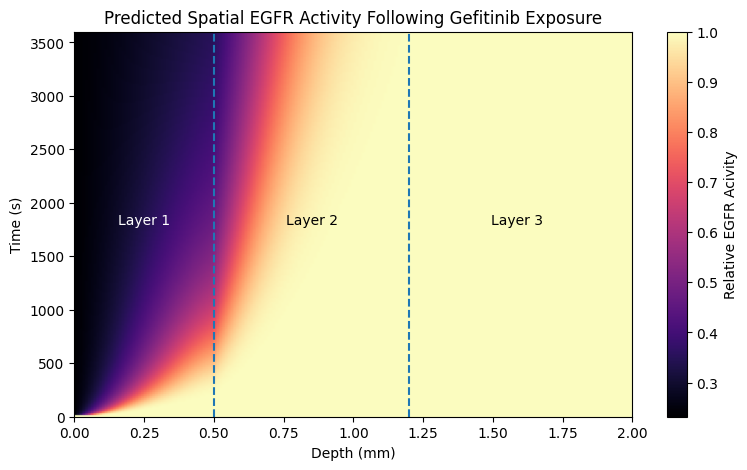

In [13]:
# Plot

plt.figure(figsize=(9, 5))

plt.imshow(EGFR_activity, aspect='auto', origin='lower', 
            extent=[0, L * 10, 0, T], cmap='magma')

# Labels and formatting

plt.colorbar(label='Relative EGFR Acivity')

plt.xlabel('Depth (mm)')
plt.ylabel('Time (s)')

plt.title('Predicted Spatial EGFR Activity Following Gefitinib Exposure')

plt.axvline(boundary_1 * 10, linestyle='--')
plt.axvline(boundary_2 * 10, linestyle='--')

plt.savefig(
    'figures/exp04_EGFR_inhib_field', 
    dpi=150,
    bbox_inches='tight'
)

plt.annotate('Layer 1', xy=(boundary_1 * 5, T / 2), fontsize=10, ha='center', color='white')
plt.annotate('Layer 2', xy=((boundary_1 + boundary_2) * 5, T / 2), fontsize=10, ha='center')
plt.annotate('Layer 3', xy=((boundary_1 + boundary_2 + L) * 8.57 / 2, T / 2), fontsize=10, ha='center')

plt.show()

## Figure 4B

**Figure 4B.** Predicted spatial distribution of relative EGFR activity following application of the Hill inhibition model to the heterogeneous gefitinib concentration field. Regions exposed to higher gefitinib concentrations exhibit greater EGFR inhibition (lower relative activity), while deeper regions receiving reduced drug exposure retain higher receptor activity. The nonlinear concentration–response relationship amplifies differences in receptor activity near the IC₅₀, producing spatially heterogeneous signaling across the tumor.

### Observations

* Application of the Hill inhibition model transformed the heterogeneous gefitinib concentration field into a corresponding spatial map of relative EGFR activity
* Regions adjacent to the vascular source exhibited the lowest EGFR activity due to high local drug concentrations, whereas receptor activity progressively increased with tissue depth as gefitinib concentrations declined
* The transition from inhibited to active receptor states occurred most prominently near the dense tissue layer, where reductions in drug penetration produced a noticeable spatial shift in EGFR activity

### Interpretation

The results demonstrate that spatial variability in drug exposure directly generates heterogeneous EGFR inhibition throughout the tumor. Because the Hill equation describes a nonlinear concentration–response relationship, receptor activity changes most rapidly when local gefitinib concentrations approach the IC₅₀. Consequently, relatively modest concentration differences produced by heterogeneous diffusion are translated into substantially larger differences in receptor activity. This establishes EGFR signaling as the first biological process through which physical transport heterogeneity influences cellular behavior.

### Discussion

The predicted EGFR activity field provides a mechanistic link between drug transport and downstream signaling. Although all tumor regions are exposed to the same vascular drug source, heterogeneous tissue structure generates unequal local concentrations that produce distinct levels of receptor inhibition across the tissue. These results suggest that transport limitations alone may permit portions of a tumor to maintain significant EGFR signaling despite targeted therapy, potentially contributing to spatially heterogeneous therapeutic responses. The EGFR activity map therefore serves as the biological input for subsequent modeling of ERK signaling and proliferation, allowing the downstream consequences of diffusion-mediated heterogeneity to be quantitatively investigated.

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Paramters

# ERK activation rate constant
k_act = 0.1

# ERK deactivation rate constant
k_deact = 0.3

# Effective signal gain, balance between ERK activation/deactivation
alpha = k_act / k_deact

# ERK activity profile
ERK_activity = alpha * EGFR_activity

**Note:** These parameters arise from the use of a first-order ODE to represent the activity of ERK (Extracellular Signal-Regulated Kinase) through the EGFR signaling pathway. The full equation is : 

$$\frac{dERK}{dt} = k_{act} * EGFR - k_{deact} * ERK$$

In particular, the solution presented in this experiment is a steady-state solution, where the first-order ERK-time derivative is set to $0$. This creates an equilibrium between ERK activation and deactivation, and solving the equation for ERK yields the following :

$$ERK = \frac{k_{act}}{k_{deact}} * EGFR$$

Additionally, the term $\frac{k_{act}}{k_{deact}}$ has been exchanged for $\alpha$, and acts as a 'signal gain' constant derived from the ratio of the two rate constants, amplifying or reducing the activity.

So, in all, the final equation used here is as written :

$$ERK = \alpha * EGFR$$

$$\alpha = \frac{k_{act}}{k_{deact}}$$

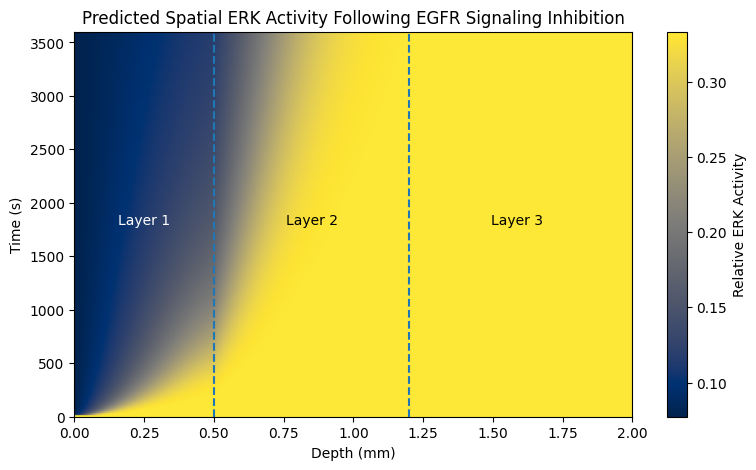

In [15]:
# Plot

plt.figure(figsize=(9,5))

plt.imshow(ERK_activity, aspect='auto', origin='lower', 
            extent=[0, L * 10, 0, T], cmap='cividis')

# Labels and formatting

plt.colorbar(label='Relative ERK Activity')

plt.xlabel('Depth (mm)')
plt.ylabel('Time (s)')

plt.title('Predicted Spatial ERK Activity Following EGFR Signaling Inhibition')

plt.axvline(boundary_1 * 10, linestyle='--')
plt.axvline(boundary_2 * 10, linestyle='--')

plt.savefig(
    'figures/exp04_ERK_activity_field', 
    dpi=150,
    bbox_inches='tight'
)

plt.annotate('Layer 1', xy=(boundary_1 * 5, T / 2), fontsize=10, ha='center', color='white')
plt.annotate('Layer 2', xy=((boundary_1 + boundary_2) * 5, T / 2), fontsize=10, ha='center')
plt.annotate('Layer 3', xy=((boundary_1 + boundary_2 + L) * 8.57 / 2, T / 2), fontsize=10, ha='center')

plt.show()

## Figure 4C

**Figure 4C.** Predicted spatial distribution of relative ERK signaling activity calculated using the steady-state solution of a first-order activation–deactivation signaling model. ERK activity is assumed to rapidly equilibrate with local EGFR activity, allowing downstream signaling to be estimated as a function of receptor activation. Regions with stronger EGFR inhibition exhibit correspondingly reduced ERK signaling, while areas receiving lower drug exposure retain higher signaling activity.

### Observations

* The spatial distribution of ERK activity closely followed the predicted EGFR activity field
* Regions adjacent to the vascular source exhibited the lowest ERK activity due to strong upstream EGFR inhibition
* ERK signaling progressively increased with tissue depth as local drug concentrations declined
* The transition in ERK activity remained most pronounced across the dense tissue layer (emphasizes the importance of heterogenous drug diffusion on intracellular signaling)

### Interpretation

The steady-state signaling model demonstrates that spatial differences in receptor inhibition propagate directly into the intracellular signaling network. Because ERK activity is determined by the balance between activation and deactivation processes, regions experiencing greater EGFR inhibition maintain correspondingly lower ERK signaling. Although simplified, this first-order model captures the essential relationship between receptor activity and downstream pathway output while preserving the mechanistic link between drug transport and cellular signaling.

### Discussion

The ERK activity field represents the first intracellular consequence of heterogeneous gefitinib delivery. Rather than modeling the complete RAS–RAF–MEK–ERK cascade, the present model approximates ERK dynamics using a first-order activation–deactivation process under a quasi-steady-state assumption. This approach preserves the biological role of ERK as the primary downstream effector of EGFR signaling while avoiding unnecessary complexity and parameter uncertainty.

The quasi-steady-state assumption is appropriate for the present study because the objective is to characterize spatial differences in signaling activity rather than transient intracellular dynamics.

The resulting ERK activity map provides the signaling input for the proliferation model, allowing the effects of spatially heterogeneous pathway inhibition to be translated into predicted differences in cellular proliferation.

In [16]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters

# Proliferation Hill coefficient
m = 4

# Half-maximal ERK activity
K = 0.5

# Proliferation rate profile
P_rate = (ERK_activity ** m) / ((K ** m) + (ERK_activity ** m))

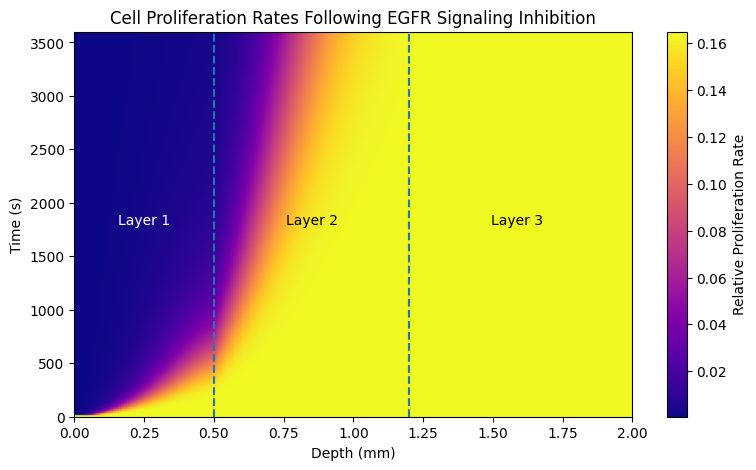

In [17]:
# Plot

plt.figure(figsize=(9,5))

plt.imshow(P_rate, aspect='auto', origin='lower', 
            extent=[0, L * 10, 0, T], cmap='plasma')

# Labels and formatting

plt.colorbar(label='Relative Proliferation Rate')

plt.xlabel('Depth (mm)')
plt.ylabel('Time (s)')

plt.title('Cell Proliferation Rates Following EGFR Signaling Inhibition')

plt.axvline(boundary_1 * 10, linestyle='--')
plt.axvline(boundary_2 * 10, linestyle='--')

plt.savefig(
    'figures/exp04_prolif_field', 
    dpi=150,
    bbox_inches='tight'
)

plt.annotate('Layer 1', xy=(boundary_1 * 5, T / 2), fontsize=10, ha='center', color='white')
plt.annotate('Layer 2', xy=((boundary_1 + boundary_2) * 5, T / 2), fontsize=10, ha='center')
plt.annotate('Layer 3', xy=((boundary_1 + boundary_2 + L) * 8.57 / 2, T / 2), fontsize=10, ha='center')

plt.show()

## Figure 4D

**Figure 4D.** Predicted spatial distribution of relative cellular proliferation following propagation of heterogeneous gefitinib exposure through EGFR inhibition and downstream ERK signaling. Relative proliferation was estimated using a Hill-type response model relating ERK activity to cell-cycle progression. Regions experiencing stronger pathway suppression exhibited reduced proliferative activity, whereas areas with limited drug penetration retained higher predicted proliferation.

### Observations

Relative proliferation was lowest in regions adjacent to the vascular source, where gefitinib concentrations and EGFR inhibition were greatest. Proliferation progressively increased with tissue depth as drug concentrations declined and ERK signaling recovered. The dense middle tissue layer produced a distinct transition in proliferative activity, resulting in pronounced spatial heterogeneity across the tumor.

### Interpretation

The proliferation map demonstrates how physical transport heterogeneity ultimately translates into heterogeneous cellular behavior. While diffusion establishes concentration gradients and EGFR inhibition modifies receptor activity, the downstream signaling cascade determines the extent to which these molecular changes influence cell-cycle progression. The nonlinear proliferation response further amplifies differences in signaling activity, producing localized regions of reduced and sustained cellular proliferation.

### Discussion

The predicted proliferation field directly addresses the central research question by illustrating how heterogeneous gefitinib transport can generate spatially heterogeneous therapeutic responses within an L858R-mutant NSCLC tumor. Despite uniform drug administration from the vascular boundary, variations in tissue transport produce unequal pathway inhibition that propagates through EGFR and ERK signaling to influence cellular proliferation. These findings suggest that transport-limited regions may remain proliferative even when neighboring tissue experiences substantial pathway suppression. More broadly, the model highlights the importance of integrating physical transport processes with intracellular signaling when evaluating targeted therapy efficacy and provides a framework that can be extended to incorporate additional biological mechanisms or alternative therapeutic strategies.

## Experiment 4 Summary

Experiment 4 integrated the physical transport model developed in the previous experiments with a simplified systems biology framework to investigate how spatial differences in gefitinib exposure translate into heterogeneous cellular responses. The heterogeneous concentration field generated from the layered tissue model was used to compute local EGFR activity through a Hill inhibition model, demonstrating that variations in drug concentration produce nonlinear differences in receptor inhibition across the tumor. These changes in EGFR activity were then propagated through a simplified ERK signaling model and subsequently mapped to proliferation using a Hill-type response function. Collectively, these results demonstrate that transport-induced concentration gradients are amplified through intracellular signaling networks to generate spatially heterogeneous proliferation patterns. Rather than simply predicting where drug concentrations are high or low, the coupled model illustrates how physical transport phenomena influence downstream biological behavior, providing a mechanistic link between drug delivery, signal transduction, and therapeutic response. This experiment therefore directly addresses the central research question by showing how heterogeneous intratumoral drug distribution gives rise to heterogeneous proliferation through differential EGFR pathway inhibition.

## Transition to Experiment 5

While the preceding experiments establish a mechanistic relationship between drug transport, EGFR inhibition, intracellular signaling, and cellular proliferation, each stage of the model depends on biological and physical parameters that vary across tumors and experimental conditions. Diffusion coefficients, inhibitor potency, signaling sensitivity, and proliferation response are all subject to uncertainty and biological variability. Consequently, evaluating the robustness of the model requires determining which parameters exert the greatest influence on the predicted therapeutic response. Experiment 5 addresses this question through a systematic sensitivity analysis, in which key transport and signaling parameters are varied within physiologically relevant ranges to quantify their effects on tumor proliferation. By identifying the dominant response drivers, this analysis not only assesses the stability of the model but also highlights the biological processes that may represent the most effective targets for improving drug delivery and therapeutic efficacy.